In [2]:
# !pip install pandas
import matplotlib.pyplot as plt
import pandas as pd

import networkx as nx
import requests
import numpy as np
# import networks_layouts
from matplotlib import colors
import pickle

import ast
def convert_str_to_list(x):
    try:
        return ast.literal_eval(x, '|')
    except:
        return None
def read_pickle(file_name):
    '''Function to read pickles faster'''
    pickle_in = open(file_name, 'rb')
    variable = pickle.load(pickle_in)
    return variable

def write_pickle(variable, file_name):
    '''Function to write pickles faster'''
    pickle_out = open(file_name, 'wb')
    pickle.dump(variable, pickle_out)

#Move all files of one folder to another one:
from os import listdir
from os.path import isfile, join
import os
import shutil


In [56]:
Filtered_DataFrame_out_filt = read_pickle('Filtered_DataFrame_out_filt_new.pkl')

In [57]:
Filtered_DataFrame_out_filt['id'] = [i.replace('https://openalex.org/','') for i in Filtered_DataFrame_out_filt['id']]

In [58]:
Filtered_DataFrame_out_filt = Filtered_DataFrame_out_filt[Filtered_DataFrame_out_filt.publication_year>=2000]

In [59]:
dict_references = read_pickle('dict_references_multi_lingual.pkl')

In [60]:
file_1 = 'Dict_of_terms/Dictionary_of_terms_Hegemonic_centric.csv'
file_2 = 'Dict_of_terms/Dictionary_of_terms_local_turn_critical_paradigms.csv'
file_3 = 'Dict_of_terms/Dictionary_of_terms_feminist_security_studies_critical_paradigms.csv'
file_4 = 'Dict_of_terms/Dictionary_of_terms_decolonial_thought_critical_paradigms.csv'

In [61]:
# !pip install statsmodels
import sys

import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(1, '/opt/anaconda3/lib/python3.13/site-package')
from statsmodels.distributions.empirical_distribution import ECDF


In [62]:
# !pip install seaborn
import matplotlib
sys.path.insert(1, '/opt/anaconda3/lib/python3.13/site-packages')
import seaborn as sns
customPalette = dict()
import colorsys

def scale_lightness(rgb, scale_l):
    # convert rgb to hls
    h, l, s = colorsys.rgb_to_hls(*rgb)
    # manipulate h, l, s values and return as rgb
    return colorsys.hls_to_rgb(h, min(1, l * scale_l), s = s)

def create_custom_palette_for_KDE():

    color = matplotlib.colors.ColorConverter.to_rgb('gray')
    rgbs = [scale_lightness(color, scale) for scale in np.arange(0, 1, 0.2)]
    customPalette = sns.set_palette(sns.color_palette(rgbs))
    sns.palplot(rgbs)
    return customPalette

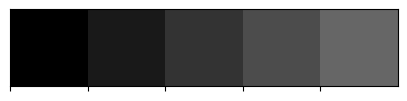

In [63]:
customPalette = create_custom_palette_for_KDE()

In [64]:
def get_continuous_cmap(name_color, lim_min, lim_max,float_list=None):
    ''' creates and returns a color map that can be used in heat map figures.
        If float_list is not provided, colour map graduates linearly between each color in hex_list.
        If float_list is provided, each color in hex_list is mapped to the respective location in float_list. 
        
        Parameters
        ----------
        hex_list: list of hex code strings
        float_list: list of floats between 0 and 1, same length as hex_list. Must start with 0 and end with 1.
        
        Returns
        ----------
        colour map'''
    color = matplotlib.colors.ColorConverter.to_rgb(name_color)
    rgb_list = [scale_lightness(color, scale) for scale in np.arange(lim_min, lim_max, 0.1)[::-1]]
    
    if float_list:
        pass
    else:
        float_list = list(np.linspace(0,1,len(rgb_list)))
        
    cdict = dict()
    for num, col in enumerate(['red', 'green', 'blue']):
        col_list = [[float_list[i], rgb_list[i][num], rgb_list[i][num]] for i in range(len(float_list))]
        cdict[col] = col_list
    cmp = matplotlib.colors.LinearSegmentedColormap('my_cmp', segmentdata=cdict, N=256)
    return cmp

Security
Political order
Peacekeeping
State-building
Conflict resolution
Democratic peace
Human rights
Peacebuilding
Governance
Reconciliation
Development
[ 0  1  2  3  4  5  6  7  8  9 10]
Security
Political order
Peacekeeping
State-building
Conflict resolution
Democratic peace
Human rights
Peacebuilding
Governance
Reconciliation
Development
[ 0  1  2  3  4  5  6  7  8  9 10]


<Figure size 640x480 with 0 Axes>

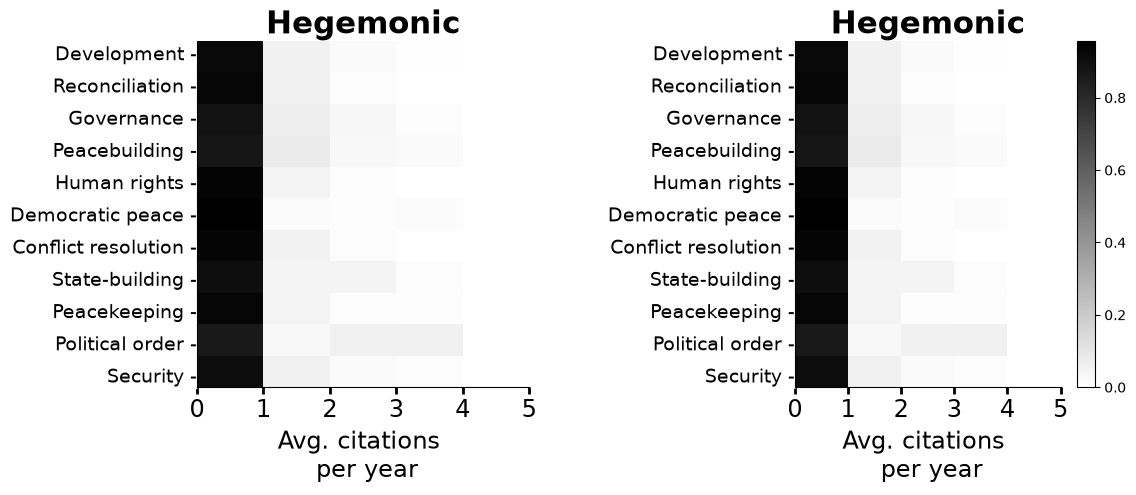

In [65]:
ncols = 2
nrows = 1
fig = plt.figure()
fig, ax = plt.subplots(ncols=ncols, nrows=nrows,figsize=(6*ncols,4.5*nrows), sharex= False, sharey= False,
                   gridspec_kw={'width_ratios': ncols*[0.5], 'height_ratios': nrows*[0.9]})

fig.subplots_adjust(wspace=0.17)
lim_min= [0]*nrows
lim_max = [2.05]*nrows
vmax = [0.6,0.45,0.27]
font_size_out = 12

row_plt = 0
col_plt = 1
name_plot = ['Hegemonic','Hegemonic']
terms = {'Hegemonic':['Security', 'Political order', 'Peacekeeping', 'State-building', 'Conflict resolution',
                      'Democratic peace', 'Human rights', 'Peacebuilding', 'Governance', 'Reconciliation', 'Development'],
        'Local turn':['Liberal peace', 'Local turn', 'Everyday peace', 'Hybridity', 'Participation', 'Community resilience', 'Grassroots peace', 'Community-led initiatives'],
         'Feminist security':['Feminist Peace', 'Care', 'Intersectionality', 'Continuum of violence'],
         'Decolonial thought':['Self-determination', 'Self-government','Restorative justice', 'Pluriversal peace',
                               'Decolonial peace', 'Indigenous sovereignty']
}


Max_x = 5
Ranges_rank_citations = np.arange(0,Max_x,1)
Total_citations = np.linspace(0,Max_x,len(Ranges_rank_citations))

for col_plt in range(ncols):

    List_Frequencies = []

    file = [file_1,file_1][col_plt]
    
    Dictionary_of_terms_institutional = pd.read_table(file,delimiter=';',header=0)
    prob_passing = 0.65
    
    # terms = list(Dictionary_of_terms_institutional.Term)

    distributions = {'term':[], 'value':[]}
    for term in terms[name_plot[col_plt]]:
        print(term)
        array_values = list(np.array(Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+term].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+term]=='Yes')].cited_by_count)/np.array(2027-Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+term].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+term]=='Yes')].publication_year))
        distributions['term'] += [term]*len(array_values)
        distributions['value'] += array_values

    distributions = pd.DataFrame(distributions)
    Ranges_rank_var = np.arange(0,len(terms[name_plot[col_plt]]),1)
    
    for term in terms[name_plot[col_plt]]:
        
        
        Citations_2020 = list(distributions[distributions.term == term].value)
            
        #Take those with citations smaller that 2 std:
        Mean_cit = np.mean(Citations_2020)
        Std_cit = np.std(Citations_2020)
        Cit_index = [i for i,cit in enumerate(Citations_2020) if cit < Mean_cit+2*Std_cit]
        
        Citations_2020 = [Citations_2020[i] for i in Cit_index]
        Sum = 0
        Freq_List_cit_var_range = [[len([ j for j in Citations_2020 if j >= val_cit and  j < Ranges_rank_citations[ix_list+1]]) for ix_list, val_cit in enumerate(Ranges_rank_citations[:-1])]]    
        Sum = sum(Freq_List_cit_var_range[-1])
        if Sum != 0:
            List_Frequencies += [[j/Sum for j in Freq_List_cit_var_range[-1]]]
        else:
            List_Frequencies += [[0 for j in Freq_List_cit_var_range[-1]]]
            

    x_values = Total_citations
    y_values = Ranges_rank_var
    print(y_values)
    z_values = List_Frequencies
    extent = [0, 4, min(x_values), max(x_values), ]

    
    ax[col_plt].imshow(np.array(z_values), extent=extent, origin='lower',cmap=get_continuous_cmap('gray',lim_min= lim_min[row_plt], 
                       lim_max = lim_max[row_plt]), aspect='auto')

    ax[col_plt].xaxis.set_major_locator(plt.MaxNLocator(5))
    ax[col_plt].set_xlim(0,5)
    # ax[col_plt].yaxis.set_major_locator(plt.MaxNLocator(len(terms)))
    ax[col_plt].tick_params('x', size=5, colors="black", labelsize=font_size_out+5)
    ax[col_plt].set_xlabel('Avg. citations \n per year',  size=font_size_out+5)

    
    ax[col_plt].text(0.5, 1, name_plot[col_plt], horizontalalignment='center',
                            verticalalignment='bottom',weight="bold",
                            fontsize=font_size_out+10, 
                            transform=ax[col_plt].transAxes, rotation='horizontal')

    for y_position, term in enumerate(terms[name_plot[col_plt]]):
        ax[col_plt].text(0, y_position*5/(len(terms[name_plot[col_plt]])-0.25), term+' -', horizontalalignment='right',
                            verticalalignment='bottom',weight="medium",
                            fontsize=font_size_out+2, rotation='horizontal')

    ax[col_plt].tick_params('y', size=0, colors="white", labelsize=0)
    ax[col_plt].set_ylabel(' ',  size=0)
        
    ax[col_plt].spines['right'].set_visible(False)
    ax[col_plt].spines['top'].set_visible(False)
    ax[col_plt].yaxis.set_ticks_position('left')
    ax[col_plt].xaxis.set_ticks_position('bottom')

    ax[col_plt].xaxis.set_tick_params(width=2, length=5)
    ax[col_plt].yaxis.set_tick_params(width=2, length=5)
    
    im = ax[col_plt].imshow(np.array(z_values), extent=extent, origin='lower',cmap=get_continuous_cmap('gray',lim_min= lim_min[row_plt], 
                    lim_max = lim_max[row_plt]), aspect='auto')
    if col_plt == 1:
        plt.colorbar(im, ax=ax[col_plt])
plt.subplots_adjust(wspace=0.8)
plt.savefig("Avg_citations_hegemonic_paradigms.pdf", bbox_inches='tight')
plt.show()

[0 1 2 3 4 5 6 7]
[0 1 2 3]
[0 1 2 3 4 5]


<Figure size 640x480 with 0 Axes>

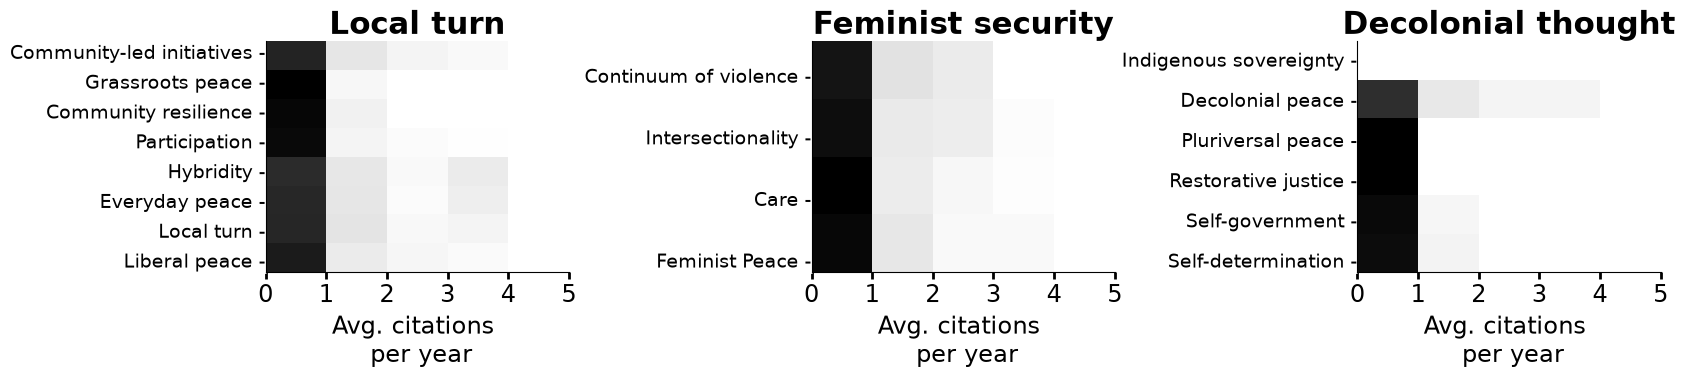

In [66]:
ncols = 3
nrows = 1
fig = plt.figure()
fig, ax = plt.subplots(ncols=ncols, nrows=nrows,figsize=(6*ncols,3*nrows), sharex= False, sharey= False,
                   gridspec_kw={'width_ratios': ncols*[0.5], 'height_ratios': nrows*[0.9]})

fig.subplots_adjust(wspace=0.17)
lim_min= [0]*nrows
lim_max = [2.05]*nrows
vmax = [0.6,0.45,0.27]
font_size_out = 12

row_plt = 0
col_plt = 1
name_plot = ['Local turn','Feminist security','Decolonial thought']
Max_x = 5
Ranges_rank_citations = np.arange(0,Max_x,1)
Total_citations = np.linspace(0,Max_x,len(Ranges_rank_citations))

for col_plt in range(ncols):

    List_Frequencies = []

    file = [file_2,file_3,file_4][col_plt]
    
    Dictionary_of_terms_institutional = pd.read_table(file,delimiter=';',header=0)
    prob_passing = 0.65
    
    terms = list(Dictionary_of_terms_institutional.Term)

    distributions = {'term':[], 'value':[]}
    for term in terms:
        array_values = list(np.array(Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+term].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+term]=='Yes')].cited_by_count)/np.array(2027-Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+term].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+term]=='Yes')].publication_year))
        distributions['term'] += [term]*len(array_values)
        distributions['value'] += array_values

    distributions = pd.DataFrame(distributions)
    Ranges_rank_var = np.arange(0,len(terms),1)
    for term in terms:
        
        
        Citations_2020 = list(distributions[distributions.term == term].value)
            
        #Take those with citations smaller that 2 std:
        Mean_cit = np.mean(Citations_2020)
        Std_cit = np.std(Citations_2020)
        Cit_index = [i for i,cit in enumerate(Citations_2020) if cit < Mean_cit+2*Std_cit]
        
        Citations_2020 = [Citations_2020[i] for i in Cit_index]
        Sum = 0
        Freq_List_cit_var_range = [[len([ j for j in Citations_2020 if j >= val_cit and  j < Ranges_rank_citations[ix_list+1]]) for ix_list, val_cit in enumerate(Ranges_rank_citations[:-1])]]    
        Sum = sum(Freq_List_cit_var_range[-1])
        if Sum != 0:
            List_Frequencies += [[j/Sum for j in Freq_List_cit_var_range[-1]]]
        else:
            List_Frequencies += [[0 for j in Freq_List_cit_var_range[-1]]]
            

    x_values = Total_citations
    y_values = Ranges_rank_var
    print(y_values)
    z_values = List_Frequencies
    extent = [0, 4, min(x_values), max(x_values), ]

    
    im = ax[col_plt].imshow(np.array(z_values), extent=extent, origin='lower',cmap=get_continuous_cmap('gray',lim_min= lim_min[row_plt], 
                       lim_max = lim_max[row_plt]), aspect='auto')

    

    ax[col_plt].xaxis.set_major_locator(plt.MaxNLocator(5))
    ax[col_plt].set_xlim(0,5)
    # ax[col_plt].yaxis.set_major_locator(plt.MaxNLocator(len(terms)))
    ax[col_plt].tick_params('x', size=5, colors="black", labelsize=font_size_out+5)
    ax[col_plt].set_xlabel('Avg. citations \n per year',  size=font_size_out+5)

    
    ax[col_plt].text(0.5, 1, name_plot[col_plt], horizontalalignment='center',
                            verticalalignment='bottom',weight="bold",
                            fontsize=font_size_out+10, 
                            transform=ax[col_plt].transAxes, rotation='horizontal')

    for y_position, term in enumerate(terms):
        ax[col_plt].text(0, y_position*5/(len(terms)-0.25), term+' -', horizontalalignment='right',
                            verticalalignment='bottom',weight="medium",
                            fontsize=font_size_out+2, rotation='horizontal')

    ax[col_plt].tick_params('y', size=0, colors="white", labelsize=0)
    ax[col_plt].set_ylabel(' ',  size=0)
        
    ax[col_plt].spines['right'].set_visible(False)
    ax[col_plt].spines['top'].set_visible(False)
    ax[col_plt].yaxis.set_ticks_position('left')
    ax[col_plt].xaxis.set_ticks_position('bottom')

    ax[col_plt].xaxis.set_tick_params(width=2, length=5)
    ax[col_plt].yaxis.set_tick_params(width=2, length=5)
plt.subplots_adjust(wspace=0.8)

plt.savefig("Avg_citations_critical_paradigms.pdf", bbox_inches='tight')
plt.show()

[ 0  1  2  3  4  5  6  7  8  9 10 11]
[ 0  1  2  3  4  5  6  7  8  9 10 11]


/var/folders/g9/w5sz99g97v16535_cc3rmjsm0000gn/T/ipykernel_70165/2850903456.py:105: UserWarning: Adding colorbar to a different Figure <Figure size 1800x300 with 3 Axes> than <Figure size 1200x400 with 3 Axes> which fig.colorbar is called on.
  plt.colorbar(im, ax=ax[col_plt])


<Figure size 640x480 with 0 Axes>

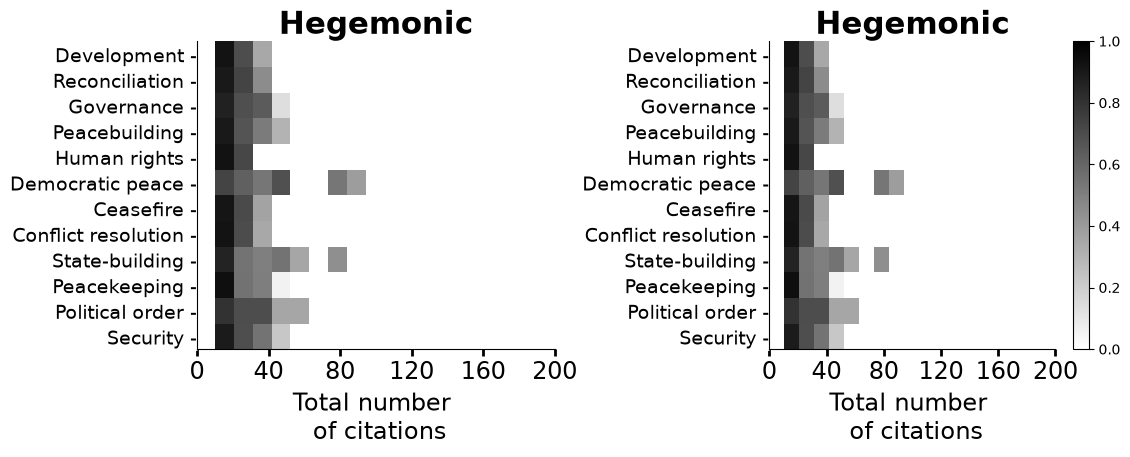

In [67]:
from matplotlib.colors import LogNorm

ncols = 2
nrows = 1
fig = plt.figure()
fig, ax = plt.subplots(ncols=ncols, nrows=nrows,figsize=(6*ncols,4*nrows), sharex= False, sharey= False,
                   gridspec_kw={'width_ratios': ncols*[0.8], 'height_ratios': nrows*[0.9]})

fig.subplots_adjust(wspace=0.17)
lim_min= [0]*nrows
lim_max = [2.05]*nrows
vmax = [0.6,0.45,0.27]
font_size_out = 12

row_plt = 0
col_plt = 1
Max_x = 200
Ranges_rank_citations = np.arange(10,Max_x,10)
Total_citations = np.linspace(10,Max_x,len(Ranges_rank_citations))

for col_plt in range(ncols):

    List_Frequencies = []

    file = [file_1,file_1][col_plt]
    
    Dictionary_of_terms_institutional = pd.read_table(file,delimiter=';',header=0)
    prob_passing = 0.65
    
    name_plots = ['Hegemonic','Hegemonic']
    terms = {'Hegemonic':['Security', 'Political order', 'Peacekeeping', 'State-building', 'Conflict resolution', 'Ceasefire',
                        'Democratic peace', 'Human rights', 'Peacebuilding', 'Governance', 'Reconciliation', 'Development'],
            'Local turn':['Liberal peace', 'Local turn', 'Everyday peace', 'Hybridity', 'Participation', 'Community resilience', 'Grassroots peace', 'Community-led initiatives'],
            'Feminist security':['Feminist Peace', 'Care', 'Intersectionality', 'Continuum of violence'],
            'Decolonial thought':['Self-determination', 'Self-government','Restorative justice', 'Pluriversal peace',
                                'Decolonial peace', 'Indigenous sovereignty']
}

    distributions = {'term':[], 'value':[]}
    for term in terms[name_plots[col_plt]]:
        array_values = list(np.array(Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+term].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+term]=='Yes')].cited_by_count))
        distributions['term'] += [term]*len(array_values)
        distributions['value'] += array_values

    distributions = pd.DataFrame(distributions)
    Ranges_rank_var = np.arange(0,len(terms[name_plots[col_plt]]),1)
    for term in terms[name_plots[col_plt]]:
        
        
        Citations_2020 = list(distributions[distributions.term == term].value)
            
        #Take those with citations smaller that 2 std:
        Mean_cit = np.mean(Citations_2020)
        Std_cit = np.std(Citations_2020)
        Cit_index = [i for i,cit in enumerate(Citations_2020) if cit < Mean_cit+2*Std_cit]
        
        Citations_2020 = [Citations_2020[i] for i in Cit_index]
        Sum = 0
        Freq_List_cit_var_range = [[len([ j for j in Citations_2020 if j >= val_cit and  j < Ranges_rank_citations[ix_list+1]]) for ix_list, val_cit in enumerate(Ranges_rank_citations[:-1])]]    
        Sum = sum(Freq_List_cit_var_range[-1])
        if Sum != 0:
            List_Frequencies += [[j/Sum for j in Freq_List_cit_var_range[-1]]]
        else:
            List_Frequencies += [[0 for j in Freq_List_cit_var_range[-1]]]
            

    x_values = Total_citations
    y_values = Ranges_rank_var
    print(y_values)
    z_values = List_Frequencies
    extent = [ min(x_values), max(x_values), 0, len(terms[name_plots[col_plt]])]

    
    ax[col_plt].imshow(np.array(z_values), extent=extent, origin='lower',cmap=get_continuous_cmap('gray',lim_min= lim_min[row_plt], 
                       lim_max = lim_max[row_plt]), aspect='auto', norm=LogNorm(vmin=0.01, vmax=1))

    ax[col_plt].xaxis.set_major_locator(plt.MaxNLocator(5))
    ax[col_plt].set_xlim(0,Max_x)
    # ax[col_plt].yaxis.set_major_locator(plt.MaxNLocator(len(terms)))
    ax[col_plt].tick_params('x', size=5, colors="black", labelsize=font_size_out+5)
    ax[col_plt].set_xlabel('Total number \n of citations',  size=font_size_out+5)

    
    ax[col_plt].text(0.5, 1, name_plots[col_plt], horizontalalignment='center',
                            verticalalignment='bottom',weight="bold",
                            fontsize=font_size_out+10, 
                            transform=ax[col_plt].transAxes, rotation='horizontal')

    for y_position, term in enumerate(terms[name_plots[col_plt]]):
        ax[col_plt].text(0, y_position*12/(len(terms[name_plots[col_plt]])), term+' -', horizontalalignment='right',
                            verticalalignment='bottom',weight="medium",
                            fontsize=font_size_out+2, rotation='horizontal')

    ax[col_plt].tick_params('y', size=0, colors="white", labelsize=0)
    ax[col_plt].set_ylabel(' ',  size=0)
        
    ax[col_plt].spines['right'].set_visible(False)
    ax[col_plt].spines['top'].set_visible(False)
    ax[col_plt].yaxis.set_ticks_position('left')
    ax[col_plt].xaxis.set_ticks_position('bottom')

    ax[col_plt].xaxis.set_tick_params(width=2, length=5)
    ax[col_plt].yaxis.set_tick_params(width=2, length=5)
    if col_plt == 1:
        plt.colorbar(im, ax=ax[col_plt])
plt.subplots_adjust(wspace=0.6)
plt.savefig("Total_citations_hegemonic_paradigms.pdf", bbox_inches='tight')
plt.show()

NameError: name 'file_5' is not defined

<Figure size 640x480 with 0 Axes>

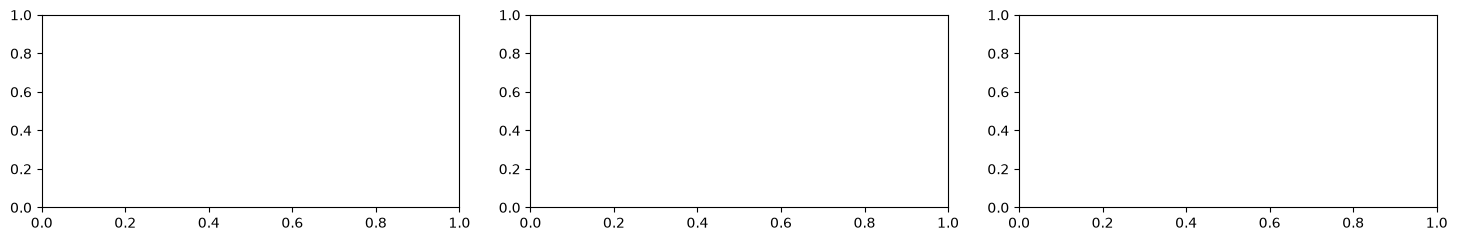

In [68]:
ncols = 3
nrows = 1
fig = plt.figure()
fig, ax = plt.subplots(ncols=ncols, nrows=nrows,figsize=(6*ncols,2.5*nrows), sharex= False, sharey= False,
                   gridspec_kw={'width_ratios': ncols*[0.5], 'height_ratios': nrows*[0.9]})

fig.subplots_adjust(wspace=0.17)
lim_min= [0]*nrows
lim_max = [2.05]*nrows
vmax = [0.6,0.45,0.27]
font_size_out = 12

row_plt = 0
col_plt = 1
name_plot = ['Local turn','Feminist security','Decolonial thought']
Max_x = 100
Ranges_rank_citations = np.arange(0,Max_x,5)
Total_citations = np.linspace(0,Max_x,len(Ranges_rank_citations))

for col_plt in range(ncols):

    List_Frequencies = []

    file = [file_4,file_5,file_6][col_plt]
    
    Dictionary_of_terms_institutional = pd.read_table(file,delimiter=';',header=0)
    prob_passing = 0.65
    
    terms = list(Dictionary_of_terms_institutional.Term)

    distributions = {'term':[], 'value':[]}
    for term in terms:
        array_values = list(np.array(Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+term].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+term]=='Yes')].cited_by_count))
        distributions['term'] += [term]*len(array_values)
        distributions['value'] += array_values

    distributions = pd.DataFrame(distributions)
    Ranges_rank_var = np.arange(0,len(terms),1)
    for term in terms:
        
        
        Citations_2020 = list(distributions[distributions.term == term].value)
            
        #Take those with citations smaller that 2 std:
        Mean_cit = np.mean(Citations_2020)
        Std_cit = np.std(Citations_2020)
        Cit_index = [i for i,cit in enumerate(Citations_2020) if cit < Mean_cit+2*Std_cit]
        
        Citations_2020 = [Citations_2020[i] for i in Cit_index]
        Sum = 0
        Freq_List_cit_var_range = [[len([ j for j in Citations_2020 if j >= val_cit and  j < Ranges_rank_citations[ix_list+1]]) for ix_list, val_cit in enumerate(Ranges_rank_citations[:-1])]]    
        Sum = sum(Freq_List_cit_var_range[-1])
        if Sum != 0:
            List_Frequencies += [[j/Sum for j in Freq_List_cit_var_range[-1]]]
        else:
            List_Frequencies += [[0 for j in Freq_List_cit_var_range[-1]]]
            

    x_values = Total_citations
    y_values = Ranges_rank_var
    print(y_values)
    z_values = List_Frequencies
    extent = [ min(x_values), max(x_values), 0, len(terms)]

    
    ax[col_plt].imshow(np.array(z_values), extent=extent, origin='lower',cmap=get_continuous_cmap('gray',lim_min= lim_min[row_plt], 
                       lim_max = lim_max[row_plt]), aspect='auto', norm=LogNorm(vmin=0.01, vmax=1))

    ax[col_plt].xaxis.set_major_locator(plt.MaxNLocator(5))
    ax[col_plt].set_xlim(0,Max_x)
    # ax[col_plt].yaxis.set_major_locator(plt.MaxNLocator(len(terms)))
    ax[col_plt].tick_params('x', size=5, colors="black", labelsize=font_size_out+5)
    ax[col_plt].set_xlabel('Total number \n of citations',  size=font_size_out+5)

    
    ax[col_plt].text(0.5, 1, name_plot[col_plt], horizontalalignment='center',
                            verticalalignment='bottom',weight="bold",
                            fontsize=font_size_out+10, 
                            transform=ax[col_plt].transAxes, rotation='horizontal')

    for y_position, term in enumerate(terms):
        if col_plt in [0]:
            ax[col_plt].text(0, y_position*8/(len(terms)), term+' -', horizontalalignment='right',
                                verticalalignment='bottom',weight="medium",
                                fontsize=font_size_out+2, rotation='horizontal')
        if col_plt in [2]:
            ax[col_plt].text(0, y_position*6/(len(terms)), term+' -', horizontalalignment='right',
                            verticalalignment='bottom',weight="medium",
                            fontsize=font_size_out+2, rotation='horizontal')
        if col_plt in [1]:
            ax[col_plt].text(0, y_position*4.5/(len(terms)), term+' -', horizontalalignment='right',
                            verticalalignment='bottom',weight="medium",
                            fontsize=font_size_out+2, rotation='horizontal')

    ax[col_plt].tick_params('y', size=0, colors="white", labelsize=0)
    ax[col_plt].set_ylabel(' ',  size=0)
        
    ax[col_plt].spines['right'].set_visible(False)
    ax[col_plt].spines['top'].set_visible(False)
    ax[col_plt].yaxis.set_ticks_position('left')
    ax[col_plt].xaxis.set_ticks_position('bottom')

    ax[col_plt].xaxis.set_tick_params(width=2, length=5)
    ax[col_plt].yaxis.set_tick_params(width=2, length=5)
plt.subplots_adjust(wspace=0.8)
plt.savefig("Total_citations_critical_paradigms.pdf", bbox_inches='tight')
plt.show()

In [435]:
# dict_citations = read_pickle('dict_citations_multi_lingual.pkl')
# dict_references = read_pickle('dict_references_multi_lingual.pkl')

In [447]:
List_broken_ids = []
Good_ids = []
for i,v in dict_references.items():
    if 'error' in v:
        List_broken_ids += [i]
    else:
        Good_ids += [i]

len(Good_ids)

List_citation_edges = []
#dict references: key is cited by content
for target in Good_ids:
    list_sources = dict_references[target]['results']
    for info_source in list_sources:
        source = info_source['id'].replace('https://openalex.org/','')
        List_citation_edges += [(source,target)]

List_broken_ids = []
Good_ids = []
for i,v in dict_citations.items():
    if 'error' in v:
        List_broken_ids += [i]
    else:
        Good_ids += [i]
#dict citations: key cites content
for source in Good_ids:
    list_targets = dict_citations[source]['results']
    for info_target in list_targets:
        target = info_target['id'].replace('https://openalex.org/','')
        List_citation_edges += [(source,target)]
    

In [449]:
import networkx as nx

In [451]:
G = nx.from_edgelist(List_citation_edges, create_using=nx.DiGraph())

In [469]:
#Remove the self-loops:
G.remove_edges_from(nx.selfloop_edges(G))
k_shell = nx.k_shell(G)
# self_loops = [ e for e in nx.selfloop_edges(G)]

In [502]:
Dict_nodes_in_shell = {}
for j in range(10):
    Dict_nodes_in_shell[j] = [n for n,k in k_shells.items() if k == j]

In [530]:
for j in range(10):
    print(j)
    for col_plt in range(3):
        file = [file_1,file_2,file_3][col_plt]
        
        Dictionary_of_terms_institutional = pd.read_table(file,delimiter=';',header=0)
        prob_passing = 0.65
        
        terms = list(Dictionary_of_terms_institutional.Term)
        for term in terms:
            smaller_DF = Filtered_DataFrame_out_filt[Filtered_DataFrame_out_filt.id.isin(Dict_nodes_in_shell[j])]
            size_term = smaller_DF[(smaller_DF['Probability_term_'+term].apply(lambda x: x[0]>=prob_passing)) | (smaller_DF['Appearance_term_'+term]=='Yes')].shape[0]
            prop_term = np.round(size_term/smaller_DF.shape[0],2)
            print(term+': '+str(prop_term))
    

0
Security: 0.12
Political order: 0.0
State-building: 0.0
Conflict resolution: 0.19
Ceasefire: 0.0
Democratic peace: 0.0
Human rights: 0.19
Peacebuilding: 0.0
Peacemaking: 0.0
Reconciliation: 0.0
Development: 0.12
Governance: 0.0
Institution-building: 0.0
Rule of law: 0.0
Peacekeeping: 0.0
Stabilization: 0.06
1
Security: 0.22
Political order: 0.0
State-building: 0.01
Conflict resolution: 0.14
Ceasefire: 0.01
Democratic peace: 0.0
Human rights: 0.1
Peacebuilding: 0.12
Peacemaking: 0.01
Reconciliation: 0.06
Development: 0.26
Governance: 0.07
Institution-building: 0.0
Rule of law: 0.02
Peacekeeping: 0.03
Stabilization: 0.01
2
Security: 0.2
Political order: 0.0
State-building: 0.01
Conflict resolution: 0.18
Ceasefire: 0.01
Democratic peace: 0.0
Human rights: 0.12
Peacebuilding: 0.12
Peacemaking: 0.01
Reconciliation: 0.07
Development: 0.25
Governance: 0.06
Institution-building: 0.0
Rule of law: 0.02
Peacekeeping: 0.03
Stabilization: 0.01
3
Security: 0.2
Political order: 0.0
State-building: 

In [531]:
for j in range(10):
    print(j)
    for col_plt in range(3):
        file = [file_4,file_5,file_6][col_plt]
        
        Dictionary_of_terms_institutional = pd.read_table(file,delimiter=';',header=0)
        prob_passing = 0.65
        
        terms = list(Dictionary_of_terms_institutional.Term)
        for term in terms:
            smaller_DF = Filtered_DataFrame_out_filt[Filtered_DataFrame_out_filt.id.isin(Dict_nodes_in_shell[j])]
            size_term = smaller_DF[(smaller_DF['Probability_term_'+term].apply(lambda x: x[0]>=prob_passing)) | (smaller_DF['Appearance_term_'+term]=='Yes')].shape[0]
            prop_term = np.round(size_term/smaller_DF.shape[0],2)
            print(term+': '+str(prop_term))

0
Liberal peace: 0.0
Local turn: 0.0
Everyday peace: 0.0
Hybridity: 0.0
Participation: 0.0
Community resilience: 0.0
Grassroots peace: 0.0
Community-led initiatives: 0.0
Feminist Peace: 0.0
Care: 0.0
Intersectionality: 0.0
Continuum of violence: 0.0
Self-determination: 0.0
Self-government: 0.0
Restorative justice: 0.0
Pluriversal peace: 0.0
Decolonial peace: 0.0
Indigenous sovereignty: 0.0
1
Liberal peace: 0.01
Local turn: 0.01
Everyday peace: 0.0
Hybridity: 0.01
Participation: 0.07
Community resilience: 0.0
Grassroots peace: 0.0
Community-led initiatives: 0.0
Feminist Peace: 0.02
Care: 0.06
Intersectionality: 0.02
Continuum of violence: 0.0
Self-determination: 0.01
Self-government: 0.01
Restorative justice: 0.02
Pluriversal peace: 0.0
Decolonial peace: 0.0
Indigenous sovereignty: 0.0
2
Liberal peace: 0.01
Local turn: 0.0
Everyday peace: 0.0
Hybridity: 0.0
Participation: 0.09
Community resilience: 0.0
Grassroots peace: 0.0
Community-led initiatives: 0.0
Feminist Peace: 0.02
Care: 0.05


In [74]:
terms = []
for col_plt in range(4):
    file = [file_1,file_2,file_3,file_4][col_plt]
    
    Dictionary_of_terms_institutional = pd.read_table(file,delimiter=';',header=0)
    terms += list(Dictionary_of_terms_institutional.Term)

In [76]:
%%time
Prop_term  = {}
terms_1 = terms
for i, term_1 in enumerate(terms_1):
    ids_term_1 = list(Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+term_1].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+term_1]=='Yes')].id)
    Prop_term[str(i+1) + '. '+term_1] = {}
    for j,term_2 in enumerate(terms_1):
        ids_term_2 = list(Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+term_2].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+term_2]=='Yes')].id)

        intersection = len(set(ids_term_1).intersection(set(ids_term_2)))
        # union = len(set(ids_term_1).union(set(ids_term_2)))
        
        Prop_term[str(i+1) + '. '+term_1][str(j+1)+'.'] = intersection/len(set(ids_term_1))


CPU times: user 16.9 s, sys: 266 ms, total: 17.1 s
Wall time: 17.4 s


In [77]:
pd.DataFrame(Prop_term).T.to_csv('Proportion_terms_with_common_papers_new.csv')
# pd.DataFrame(Prop_term).T

In [71]:
term = 'Security'
Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+term].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+term]=='Yes')].shape[0]

8684

Security
Political order
Peacekeeping
State-building
Conflict resolution
Ceasefire
Democratic peace
Human rights
Peacebuilding
Governance
Reconciliation
Development


<Figure size 640x480 with 0 Axes>

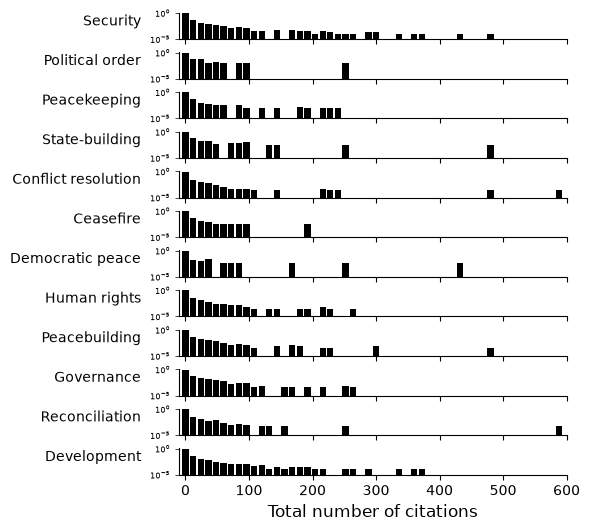

Liberal peace
Local turn
Everyday peace
Hybridity
Participation
Community resilience
Grassroots peace
Community-led initiatives


<Figure size 640x480 with 0 Axes>

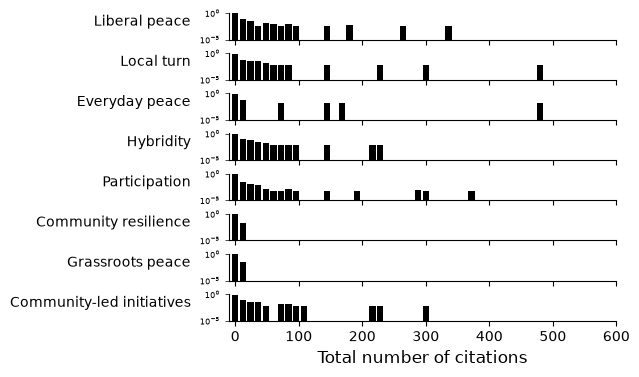

Feminist Peace
Care
Intersectionality
Continuum of violence


<Figure size 640x480 with 0 Axes>

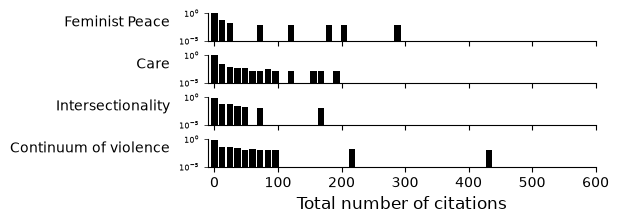

Self-determination
Self-government
Restorative justice
Pluriversal peace
Decolonial peace
Indigenous sovereignty


<Figure size 640x480 with 0 Axes>

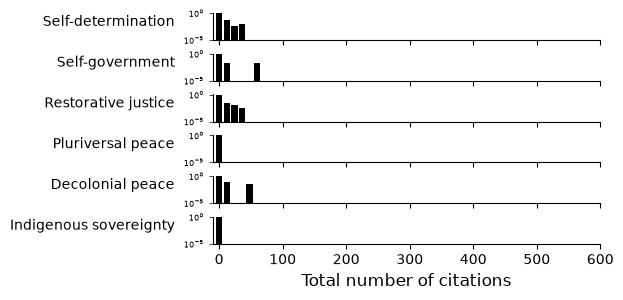

In [69]:
for t1 in terms:
    ncols = 1
    nrows = len(terms[t1])
    fig = plt.figure()
    fig, ax = plt.subplots(ncols=ncols, nrows=nrows,figsize=(5*ncols,0.5*nrows), sharex= True, sharey= True,
                       gridspec_kw={'width_ratios': ncols*[0.5], 'height_ratios': nrows*[0.8]})

    for row_plt, term in enumerate(terms[t1]):
        print(term)
        x,y = np.histogram(Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+term].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+term]=='Yes')].cited_by_count,
                          range=(0,600), bins = 50)

        
        ax[row_plt].bar(y[:-1], x/sum(x), width=10)
        ax[row_plt].set_yscale('log')
        ax[row_plt].set_xlim(-10,600)
        ax[row_plt].set_ylim(0.00001,1.1)


        # ax[row_plt].yaxis.set_major_locator(plt.MaxNLocator(5))

        ax[row_plt].tick_params('y', size=0, colors="black", labelsize=6)
        # ax[row_plt].tick_params('x', size=0, colors="black", labelsize=0)
        ax[row_plt].set_ylabel(' ',  size=0)

        ax[row_plt].text(-70, 0.001, term, horizontalalignment='right',
                            verticalalignment='bottom',weight="medium",
                            fontsize=10, rotation='horizontal')
            
        ax[row_plt].spines['right'].set_visible(False)
        ax[row_plt].spines['top'].set_visible(False)
        ax[row_plt].yaxis.set_ticks_position('left')
        # ax[row_plt].xaxis.set_ticks_position('bottom')
    
        # ax[row_plt].xaxis.set_tick_params(width=1, length=2)
        ax[row_plt].yaxis.set_tick_params(width=0.5, length=3)
        if row_plt == len(terms[t1])-1:
            ax[row_plt].set_xlabel('Total number of citations',  size=12)

    plt.subplots_adjust(hspace=0.5)
    plt.savefig("Total_citations_per_year_"+t1+".pdf", bbox_inches='tight')
    plt.show()

Security
Political order
Peacekeeping
State-building
Conflict resolution
Ceasefire
Democratic peace
Human rights
Peacebuilding
Governance
Reconciliation
Development


<Figure size 640x480 with 0 Axes>

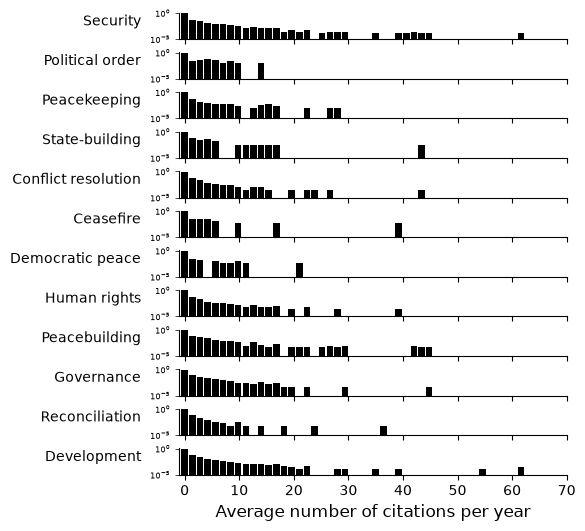

Liberal peace
Local turn
Everyday peace
Hybridity
Participation
Community resilience
Grassroots peace
Community-led initiatives


<Figure size 640x480 with 0 Axes>

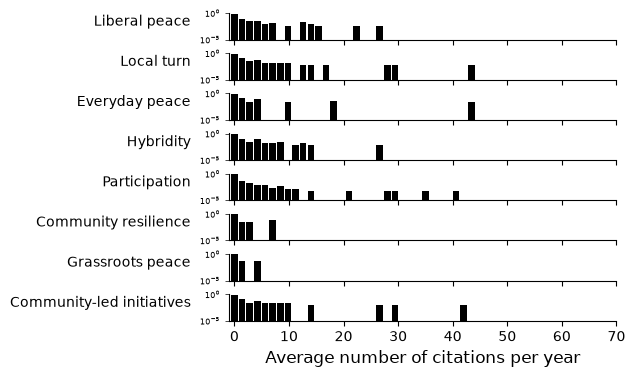

Feminist Peace
Care
Intersectionality
Continuum of violence


<Figure size 640x480 with 0 Axes>

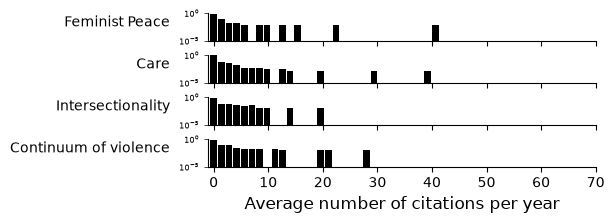

Self-determination
Self-government
Restorative justice
Pluriversal peace
Decolonial peace
Indigenous sovereignty


<Figure size 640x480 with 0 Axes>

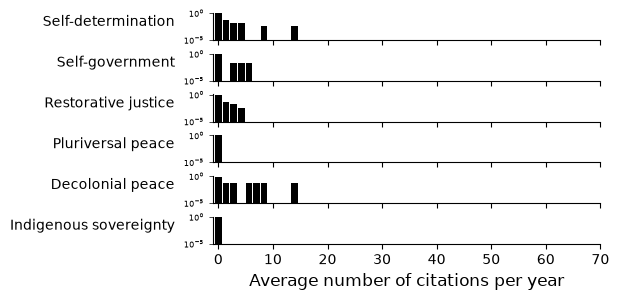

In [72]:
max_x =70
for t1 in terms:
    ncols = 1
    nrows = len(terms[t1])
    fig = plt.figure()
    fig, ax = plt.subplots(ncols=ncols, nrows=nrows,figsize=(5*ncols,0.5*nrows), sharex= True, sharey= True,
                       gridspec_kw={'width_ratios': ncols*[0.5], 'height_ratios': nrows*[0.8]})

    for row_plt, term in enumerate(terms[t1]):
        print(term)
        citations = Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+term].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+term]=='Yes')].cited_by_count
        years = Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+term].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+term]=='Yes')].publication_year
        x,y = np.histogram(citations/(2025-years),
                          range=(0,max_x), bins = 50)

        
        ax[row_plt].bar(y[:-1], x/sum(x), width=1.2)
        ax[row_plt].set_yscale('log')
        ax[row_plt].set_xlim(-1,max_x)
        ax[row_plt].set_ylim(0.00001,1.1)


        # ax[row_plt].yaxis.set_major_locator(plt.MaxNLocator(5))

        ax[row_plt].tick_params('y', size=0, colors="black", labelsize=6)
        # ax[row_plt].tick_params('x', size=0, colors="black", labelsize=0)
        ax[row_plt].set_ylabel(' ',  size=0)

        ax[row_plt].text(-8, 0.001, term, horizontalalignment='right',
                            verticalalignment='bottom',weight="medium",
                            fontsize=10, rotation='horizontal')
            
        ax[row_plt].spines['right'].set_visible(False)
        ax[row_plt].spines['top'].set_visible(False)
        ax[row_plt].yaxis.set_ticks_position('left')
        # ax[row_plt].xaxis.set_ticks_position('bottom')
    
        # ax[row_plt].xaxis.set_tick_params(width=1, length=2)
        ax[row_plt].yaxis.set_tick_params(width=0.5, length=3)
        if row_plt == len(terms[t1])-1:
            ax[row_plt].set_xlabel('Average number of citations per year',  size=12)

    plt.subplots_adjust(hspace=0.5)
    plt.savefig("Average_citations_per_year_"+t1+".pdf", bbox_inches='tight')
    plt.show()